In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text
from sklearn.metrics import accuracy_score, mean_squared_error

# Load Abalone dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"
column_names = [
    'Sex', 'Length', 'Diameter', 'Height', 'WholeWeight', 'ShuckedWeight',
    'VisceraWeight', 'ShellWeight', 'Rings'
]
abalone = pd.read_csv(url, header=None, names=column_names)

# Encode categorical variable 'Sex'
abalone['Sex'] = abalone['Sex'].map({'M': 0, 'F': 1, 'I': 2})

# Define features (X) and target (y)
X = abalone.drop(columns=['Rings'])
y_classification = (abalone['Rings'] > 10).astype(int)  # Binary classification: Rings > 10
y_regression = abalone['Rings']  # Regression target

# Split into training and testing datasets
X_train, X_test, y_train_class, y_test_class = train_test_split(X, y_classification, test_size=0.2, random_state=42)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y_regression, test_size=0.2, random_state=42)


**Recursive partitioning for classification**

In [ ]:
# Initialize Decision Tree Classifier
clf = DecisionTreeClassifier(max_depth=5, random_state=42)

# Fit the model
clf.fit(X_train, y_train_class)

# Make predictions
y_pred_class = clf.predict(X_test)

# Evaluate performance
accuracy = accuracy_score(y_test_class, y_pred_class)
print("Classification Accuracy:", accuracy)

# Display tree structure
tree_rules = export_text(clf, feature_names=list(X.columns))
print("\nDecision Tree (Classification Rules):\n", tree_rules)


Classification Accuracy: 0.7655502392344498

Decision Tree (Classification Rules):
 |--- ShellWeight <= 0.29
|   |--- ShellWeight <= 0.15
|   |   |--- Sex <= 1.50
|   |   |   |--- WholeWeight <= 0.24
|   |   |   |   |--- ShuckedWeight <= 0.06
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- ShuckedWeight >  0.06
|   |   |   |   |   |--- class: 0
|   |   |   |--- WholeWeight >  0.24
|   |   |   |   |--- ShuckedWeight <= 0.19
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- ShuckedWeight >  0.19
|   |   |   |   |   |--- class: 0
|   |   |--- Sex >  1.50
|   |   |   |--- Height <= 0.13
|   |   |   |   |--- ShellWeight <= 0.11
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- ShellWeight >  0.11
|   |   |   |   |   |--- class: 0
|   |   |   |--- Height >  0.13
|   |   |   |   |--- VisceraWeight <= 0.13
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- VisceraWeight >  0.13
|   |   |   |   |   |--- class: 1
|   |--- ShellWeight >  0.15
|   |   |--- ShuckedWeight <= 0.3

**Recursive Partitioning for Regression**

In [ ]:
# Initialize Decision Tree Regressor
reg = DecisionTreeRegressor(max_depth=5, random_state=42)

# Fit the model
reg.fit(X_train_reg, y_train_reg)

# Make predictions
y_pred_reg = reg.predict(X_test_reg)

# Evaluate performance
mse = mean_squared_error(y_test_reg, y_pred_reg)
print("Regression Mean Squared Error:", mse)

# Display tree structure
tree_rules_reg = export_text(reg, feature_names=list(X.columns))
print("\nDecision Tree (Regression Rules):\n", tree_rules_reg)


Regression Mean Squared Error: 5.365615259218499

Decision Tree (Regression Rules):
 |--- ShellWeight <= 0.15
|   |--- ShellWeight <= 0.05
|   |   |--- ShellWeight <= 0.02
|   |   |   |--- ShuckedWeight <= 0.01
|   |   |   |   |--- ShuckedWeight <= 0.00
|   |   |   |   |   |--- value: [2.00]
|   |   |   |   |--- ShuckedWeight >  0.00
|   |   |   |   |   |--- value: [3.60]
|   |   |   |--- ShuckedWeight >  0.01
|   |   |   |   |--- VisceraWeight <= 0.01
|   |   |   |   |   |--- value: [4.29]
|   |   |   |   |--- VisceraWeight >  0.01
|   |   |   |   |   |--- value: [4.87]
|   |   |--- ShellWeight >  0.02
|   |   |   |--- Diameter <= 0.22
|   |   |   |   |--- Diameter <= 0.17
|   |   |   |   |   |--- value: [4.33]
|   |   |   |   |--- Diameter >  0.17
|   |   |   |   |   |--- value: [5.72]
|   |   |   |--- Diameter >  0.22
|   |   |   |   |--- Length <= 0.30
|   |   |   |   |   |--- value: [7.56]
|   |   |   |   |--- Length >  0.30
|   |   |   |   |   |--- value: [6.15]
|   |--- ShellWei

**Visualization**

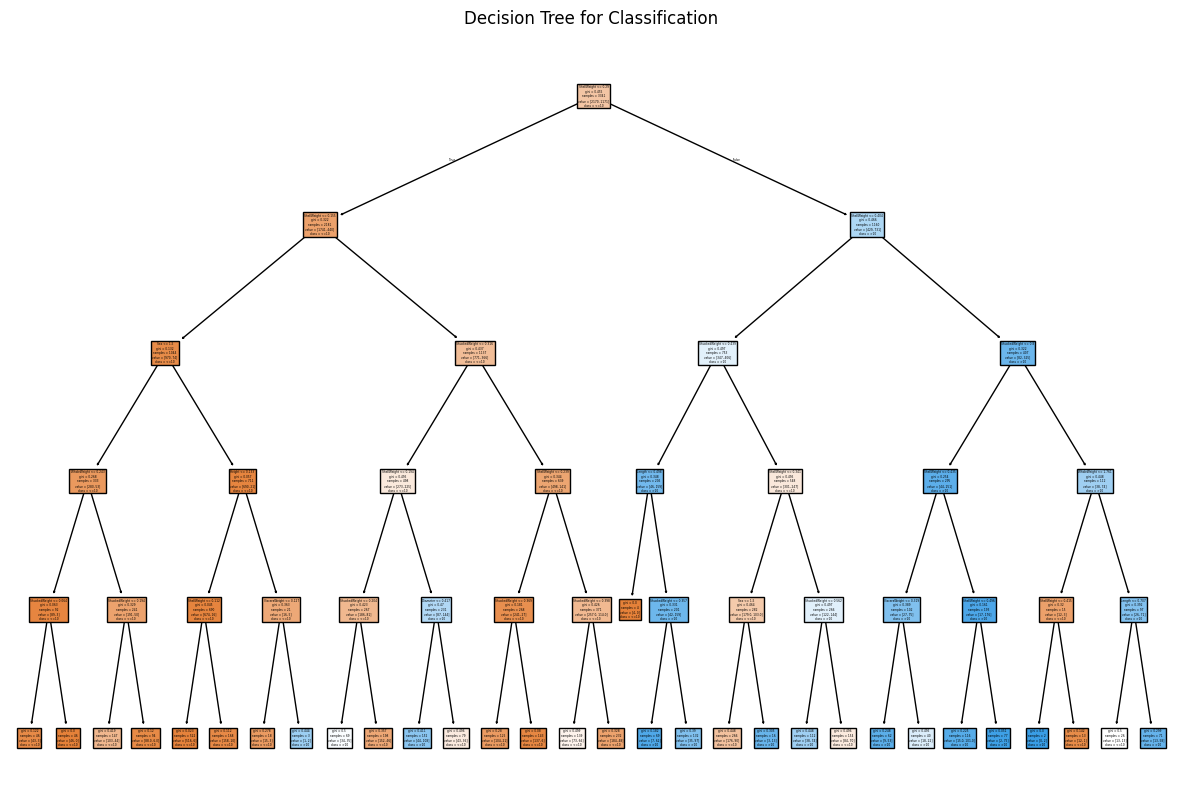

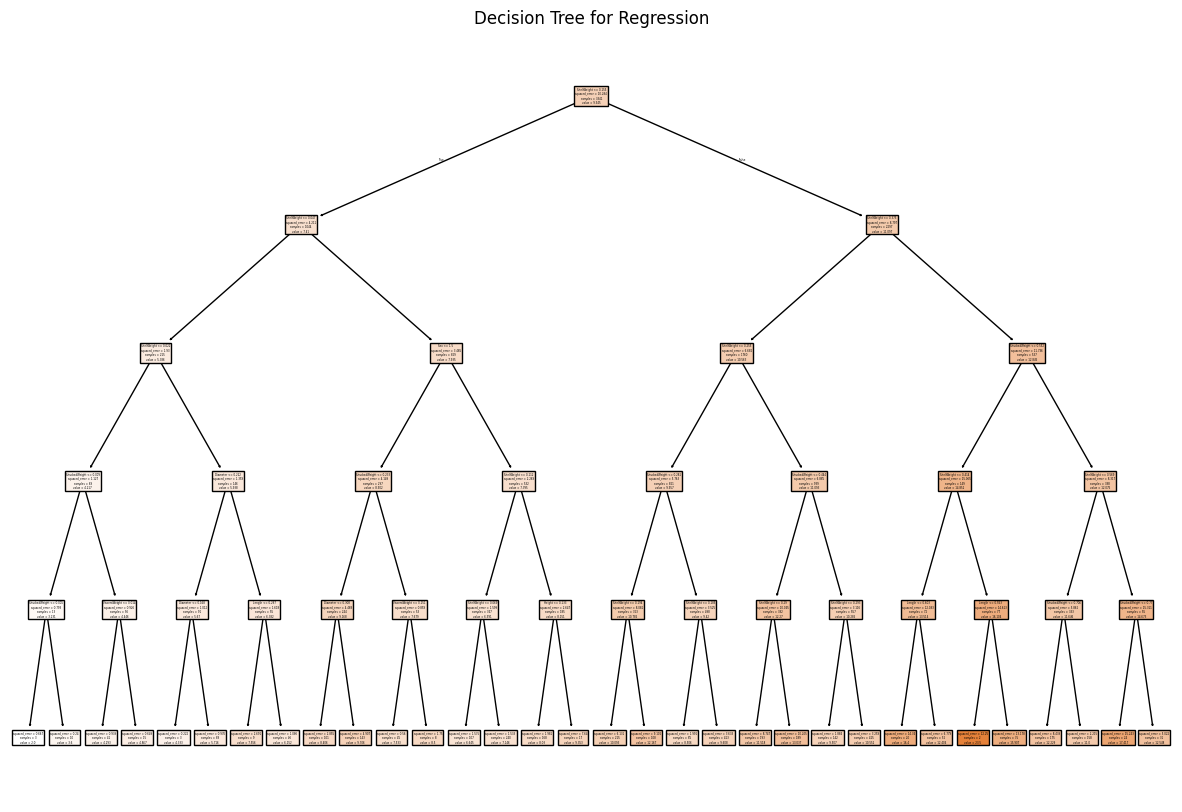

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Classification tree visualization
plt.figure(figsize=(15, 10))
plot_tree(clf, feature_names=X.columns, class_names=['<=10', '>10'], filled=True)
plt.title("Decision Tree for Classification")
plt.show()

# Regression tree visualization
plt.figure(figsize=(15, 10))
plot_tree(reg, feature_names=X.columns, filled=True)
plt.title("Decision Tree for Regression")
plt.show()


**Feature Importance**

In [ ]:
# Get feature importance for classification
classification_importance = clf.feature_importances_
classification_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': classification_importance
}).sort_values(by='Importance', ascending=False)

print("Feature Importance for Classification:\n", classification_importance_df)

# Get feature importance for regression
regression_importance = reg.feature_importances_
regression_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': regression_importance
}).sort_values(by='Importance', ascending=False)

print("\nFeature Importance for Regression:\n", regression_importance_df)


Feature Importance for Classification:
          Feature  Importance
7    ShellWeight    0.740965
5  ShuckedWeight    0.176129
0            Sex    0.024376
4    WholeWeight    0.019329
1         Length    0.014772
2       Diameter    0.011423
6  VisceraWeight    0.009821
3         Height    0.003185

Feature Importance for Regression:
          Feature  Importance
7    ShellWeight    0.809421
5  ShuckedWeight    0.140284
0            Sex    0.022911
1         Length    0.018923
2       Diameter    0.006504
3         Height    0.001429
6  VisceraWeight    0.000527
4    WholeWeight    0.000000


# **What is `feature_importances_` Based On?**

The `feature_importances_` attribute in decision tree models (e.g., `DecisionTreeClassifier` and `DecisionTreeRegressor` from scikit-learn) quantifies the importance of each feature in the model.

## **Interpretation:**
- Features with higher `feature_importances_` values are more influential in determining splits and contribute more to the predictive power of the tree.
- Features not used in any splits have a value of 0.

## **Basis of `feature_importances_`:**

1. **Impurity Reduction:**
   - It measures the **total reduction in impurity** contributed by each feature over all the nodes in the tree.
   - **Impurity** depends on the task:
     - **Classification Trees:** Use measures like the Gini Index or Entropy (Information Gain).
     - **Regression Trees:** Use measures like Variance or Mean Squared Error (MSE).

2. **Weighted Contribution:**
   - For each split in the tree:
     - Calculate the reduction in impurity achieved by splitting on a feature at a node.
     - Weight this reduction by the proportion of samples that pass through the node (i.e., the fraction of the dataset affected by this split).
   - Sum up the weighted impurity reductions for each feature across all nodes in the tree.

3. **Normalization:**
   - The importance scores are normalized so that they sum up to 1 across all features.

---

## **Formula:**

For a given feature $ j $, its importance $ I_j $ is:

$$
I_j = \sum_{t \in \text{nodes where feature } j \text{ is used}} \frac{N_t}{N} \cdot (\text{impurity before split} - \text{impurity after split})
$$

Where:
  - $ N_t $: Number of samples at node \( t \).
  - $ N $: Total number of samples in the dataset.

- **Impurity measures:**
  - **Gini Index**: $ G = 1 - \sum p_k^2 $, where $ p_k $ is the proportion of class $ k $ at the node.
  - **Entropy**: $ H = -\sum p_k \log(p_k) $.
  - **Variance** (for regression): Variance of the target variable.

---

## **Example for Classification:**
- A split reduces the Gini Index from 0.5 to 0.2 and affects 30% of the data samples.
- The contribution of this split to the feature importance would be:

$$
(0.5 - 0.2) \times 0.3 = 0.09
$$

---

## **Example for Regression:**
- A split reduces the variance from 20 to 10 and affects 40% of the data samples.
- The contribution to the feature importance would be:

$$
(20 - 10) \times 0.4 = 4
$$

---




